## Solving Non-linear Equations

---

This notebook discusses numerical methods to solve nonlinear equations.

Each method has its advantages and pitfalls. Hence, often hybrid approaches are implemented in practical numerical solvers.

Solving a non-linear equation:

1. Bisection Method
2. Secant Method
3. Newton-Raphson (Newton's method)
4. Fixed-point iteration
  
---

### References

**Notes and examples are inspired by the discussion in the following references**

* [N. S. Asaithambi, *Numerical Analysis: Theory and Practice (Chapters 2 and 5)*](https://archive.org/details/numericalanalysi0000asai)

---

In [ ]:
import numpy as np
np.set_printoptions(precision=6, suppress=True)   # readable arrays

## <span style="color:#455a64">Root finding</span>

[Root finding](https://en.wikipedia.org/wiki/Root-finding_algorithm) refers to finding solution of an equation $f(x)=0$ for some function $f(x)$.

This is a relevant problem because it comes up frequently in engineering. For example, if we want to optimize a nonlinear function $f(x)$ then we need to find critical points and therefore solve the equation $f'(x)=0$.

Convenient way to represent a non-linear function is using a polynomial:

$f(x) = a_{0} + a_{1}x + a_{2}x^2 + ... + a_{n-1}x^{n-1} + a_{n}x^{n}$

where the $a_{i}$'s are the coefficients of $f(x)$ (constants), and $a_{n} \neq 0$ gives a polynomial of degree $n$.

For a few nonlinear equations (e.g. quadratic, cubic) exact solutions exist. *However, there are many more examples of nonlinear equations for which either no known exact formula exists or is very difficult to obtain.*

<span style="color:#c62828">Question: What type of non-linear functions can we solve using the methods in this lecture?</span>

We can solve any type of function (polynomial, exponential, trigonometric, or mixed), provided it is continuous and differentiable. Some methods also require that the derivative is not zero near the root.

### Note:

* There is no universal recipe for estimating the value of a root.

* If the equation is associated with a physical problem, then the context of the problem (physical insight) might suggest the approximate location of the root. Otherwise, you may undertake a systematic numerical search for the roots.

* All methods of finding roots are **iterative procedures** that require a starting point (i.e., an estimate of the root).


### Nonlinear equation in a single variable

Here, we investigate numerical methods for solving nonlinear equation (solving for the roots, i.e., zeros) with a single independent variable.

### 1. Bisection Method (Binary Search Method)

* Simplest of the approaches
* Need two starting guesses enclosing the solution
* Also called the enclosure or bracketing method.

**Core Concept (Intermediate Value Theorem)**

If a continuous function $f(x)$ has opposite signs at points $a$ and $b$ (i.e., $f(a) \cdot f(b) < 0$), at least one root must exist within the interval $[a, b]$.

Let us *visualize* the iterative steps in the bisection method. Code adopted from reference:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import matplotlib

# Configure matplotlib to render animations natively in Jupyter
matplotlib.rc("animation", html="jshtml")

# Define the function
f = lambda x: np.cos(x) - x**3

# We will store the exact state of a, b, and p for every single frame
# Using np.nan instead of None prevents Math/TypeError crashes
a_vals = []
b_vals = []
p_vals = []

a_curr = 0.2
b_curr = 1.3
FA = f(a_curr)

# Generate the frame data (10 iterations is plenty for a visual)
for i in range(10):
    # current bounds (a and b), hide p
    a_vals.append(a_curr)
    b_vals.append(b_curr)
    p_vals.append(np.nan)

    # Calculate midpoint
    p_curr = a_curr + (b_curr - a_curr) / 2.0
    FP = f(p_curr)

    # Show the bounds AND the newly evaluated midpoint p
    a_vals.append(a_curr)
    b_vals.append(b_curr)
    p_vals.append(p_curr)

    # Check tolerance / zero condition
    if np.isclose(FP, 0.0) or (b_curr - a_curr) / 2.0 < 0.05:
        break

    # Bisection logic to update bounds for the next iteration
    if np.sign(FA) * np.sign(FP) > 0:
        a_curr = p_curr
        FA = FP
    else:
        b_curr = p_curr

# --- Plotting Setup ---
fig, ax = plt.subplots(figsize=(6, 4))

# Center the axes for a clean mathematical look
ax.spines["left"].set_position("zero")
ax.spines["right"].set_color("none")
ax.yaxis.tick_left()
ax.spines["bottom"].set_position("zero")
ax.spines["top"].set_color("none")
ax.xaxis.tick_bottom()

ax.set_xlim(-0.2, 2.0)
ax.set_ylim(-4, 4)

# Plot the main function curve
x = np.linspace(-0.2, 2.0, 200)
ax.plot(x, f(x), "k-", label=r"$f(x) = \cos(x) - x^3$")
ax.legend(loc='upper right')

# Initialize empty line and text objects for the animation to update
line_a, = ax.plot([], [], "k--")
line_b, = ax.plot([], [], "k--")
line_p, = ax.plot([], [], "r--")

text_a = ax.text(0, 0, "", fontsize=12)
text_b = ax.text(0, 0, "", fontsize=12)
text_p = ax.text(0, 0, "", fontsize=12, color="red")

def animate(i):
    av = a_vals[i]
    bv = b_vals[i]
    pv = p_vals[i]

    # i // 2 perfectly calculates the iteration number (0, 0, 1, 1, 2, 2...)
    step = i // 2

    # Update vertical lines for bounds a and b
    line_a.set_data([av, av], [0.0, f(av)])
    line_b.set_data([bv, bv], [0.0, f(bv)])

    # Position text for a and b (slightly above the curve, or at 0.2 if below axis)
    ya_pos = f(av) + 0.2 if f(av) > 0 else 0.2
    yb_pos = f(bv) + 0.2 if f(bv) > 0 else 0.2
    text_a.set_position((av - 0.05, ya_pos))
    text_b.set_position((bv - 0.05, yb_pos))

    #
    text_a.set_text(rf"$a_{{{step}}}$")
    text_b.set_text(rf"$b_{{{step}}}$")

    # Handle p (midpoint) visualization
    if np.isnan(pv):
        # p is not yet calculated, pass empty arrays to hide it
        line_p.set_data([], [])
        text_p.set_text("")
    else:
        # p is calculated, show it
        line_p.set_data([pv, pv], [0.0, f(pv)])
        yp_pos = f(pv) + 0.2 if f(pv) > 0 else 0.2
        text_p.set_position((pv - 0.05, yp_pos))
        text_p.set_text(rf"$p_{{{step}}}$")

        # Prevent text overlap when the interval gets very small
        if abs(av - pv) < 0.15:
            text_a.set_text("")
        if abs(bv - pv) < 0.15:
            text_b.set_text("")

    return line_a, line_b, line_p, text_a, text_b, text_p

# Close the static plot so only the animation renders in Jupyter
plt.close(fig)

# Generate and display the animation
ani = FuncAnimation(fig, animate, frames=len(a_vals), interval=1500)
ani

---

$f(x) = \cos(x) - x^3$ using the initial bounds $a = 0.2$ and $b = 1.3$. The process stops at a step when $\vert{}f(x^*)\vert{} < 10^{-6}$.

| $k$ | $a$ | $b$ | $x^*$ | $f(x^*)$ |
|---|---|---|---|---|
| 0 | 0.200000 | 1.300000 | 0.750000 | 0.309814 |
| 1 | 0.750000 | 1.300000 | 1.025000 | -0.557848 |
| 2 | 0.750000 | 1.025000 | 0.887500 | -0.067830 |
| 3 | 0.750000 | 0.887500 | 0.818750 | 0.134260 |
| 4 | 0.818750 | 0.887500 | 0.853125 | 0.036735 |
| 5 | 0.853125 | 0.887500 | 0.870313 | -0.014691 |
| 6 | 0.853125 | 0.870313 | 0.861719 | 0.011234 |
| 7 | 0.861719 | 0.870313 | 0.866016 | -0.001676 |
| 8 | 0.861719 | 0.866016 | 0.863867 | 0.004792 |
| 9 | 0.863867 | 0.866016 | 0.864941 | 0.001561 |
| 10 | 0.864941 | 0.866016 | 0.865479 | -0.000057 |
| 11 | 0.864941 | 0.865479 | 0.865210 | 0.000752 |
| 12 | 0.865210 | 0.865479 | 0.865344 | 0.000348 |
| 13 | 0.865344 | 0.865479 | 0.865411 | 0.000146 |
| 14 | 0.865411 | 0.865479 | 0.865445 | 0.000044 |
| 15 | 0.865445 | 0.865479 | 0.865462 | -0.000006 |
| 16 | 0.865445 | 0.865462 | 0.865453 | 0.000019 |
| 17 | 0.865453 | 0.865462 | 0.865458 | 0.000007 |
| 18 | 0.865458 | 0.865462 | 0.865460 | 0.000000 |

---

By repeatedly halving the interval, we trap the root in a continuously shrinking window.

#### Algorithm
1. **Initialize:** Choose starting bounds $a$ and $b$, a tolerance $\epsilon$ (e.g., $10^{-6}$), and maximum iterations $N_{\text{max}}$.
2. **Bracket Check:** If $f(a) \cdot f(b) > 0$, abort. The bounds do not guarantee a root.
3. **Iterate (up to $N_{\text{max}}$ times):**
   * **Bisect:** Calculate the midpoint $c = a + \frac{b - a}{2}$.
   * **Evaluate & Stop:** If $f(c) = 0$ (exact root) or the interval error $\frac{b-a}{2} < \epsilon$, stop and return $c$.
   * **Update Bounds:**
     * If $f(a) \cdot f(c) < 0$, the root is in the left half $\implies$ update $b = c$.
     * Otherwise, the root is in the right half $\implies$ update $a = c$.
4. **Timeout:** If $N_{\text{max}}$ is reached without meeting the tolerance, raise a convergence warning.

---

### Stopping criteria

The bisection is repeated until the interval has been reduced to a small value $varepsilonε$

$$|\Delta x | = | x_n - x_{n-1} | < \varepsilon$$

In each iteration step $|\Delta x |$ reduces to $|\Delta x |/2$. After $n$ iterations:

$$\frac{|\Delta x |}{2^n} = \varepsilon$$

$$ n = \frac{\mathrm{ln}(|\Delta x |/\varepsilon)}{\mathrm{ln}(2)}$$

* $n$ : must be an interger

In [ ]:
import numpy as np

def bisection(f, a, b, tol=1e-6, max_iter=100):

    # Step 1: Evaluate initial bounds
    f_a = f(a)
    f_b = f(b)

    # Step 2: Bracket check
    if f_a * f_b > 0:
        raise ValueError(f"Root is not bracketed. f({a}) = {f_a:.4f} and f({b}) = {f_b:.4f} have the same sign.")

    # Step 3: Iterate
    for i in range(1, max_iter + 1):
        # Calculate midpoint safely (prevents numerical overflow)
        c = a + (b - a) / 2.0
        f_c = f(c)

        # Check stopping criteria (exact root or within tolerance)
        if f_c == 0.0 or (b - a) / 2.0 < tol:
            print(f"Converged strictly after {i} iterations.")
            return c

        # Update the correct bound
        if f_a * f_c < 0:
            b = c      # Root is in the left half
            # f_b = f_c (Not strictly needed for the next loop's logic, but good practice)
        else:
            a = c      # Root is in the right half
            f_a = f_c  # We must update f_a since it's used in the if-condition

    # Step 4: Timeout
    raise RuntimeError(f"Method failed to converge within {max_iter} iterations.")

### Example

In [ ]:
### Define a function
def f(x):
    return x**3 - 2.*x - 5.0

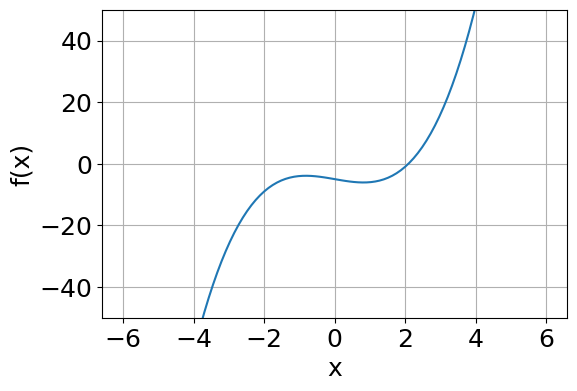

In [ ]:
## Plotting the functions using matlpotlib
plt.rc("font", size=18)

x = np.linspace(-6, 6, 100)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x, f(x))

ax.set(xlabel='x', ylabel='f(x)')
ax.set_ylim(-50, 50)
ax.set_xticks(np.arange(-6, 6.01,2))

ax.grid()

plt.show()

In [ ]:
a = 2.0
b = 3.0

root = bisection(f, a, b)
print('root =', root)
print('func val =', f(root))

Converged strictly after 20 iterations.
root = 2.0945520401000977
func val = 6.234309738673005e-06


### 2. Secant Method (Method based on Linear interpolation)

* Need two starting guesses, not necessarily enclosing the solution
* The idea is to use linearization help find the root

**Core Concept:**
The equation of secant line joining $(a, f(a))$ and $(b, f(b))$:

$y - f(b) = \frac{f(b) - f(a)}{b - a}(x - b)$

The secant line intersects the x-axis at:

$x^{*} = b - \frac{f(b)(b - a)}{f(b) - f(a)}$

For the next iteration, we simply set $a = b$ and $b = x^{*}$ and calculate the next approximation $x^{*}$

**Visualize the algorithm:**

Let us visualize the iterative steps in the secant method.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# 1. Define the function
def f(x):
    return np.cos(x) - x**3

# 2. Pre-compute the Secant iterations
x_history = [0.2, 1.3]  # Initial guesses: a and b
max_frames = 6          # Secant converges very quickly

for _ in range(max_frames):
    x_prev = x_history[-2]
    x_curr = x_history[-1]

    f_prev = f(x_prev)
    f_curr = f(x_curr)

    # Secant update step
    # Note: Denominator check is omitted here for animation simplicity,
    # but critical for production code to avoid division by zero!
    x_next = x_curr - f_curr * (x_curr - x_prev) / (f_curr - f_prev)
    x_history.append(x_next)

# 3. Set up the Matplotlib figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
#fig.subplots_adjust(right=0.6)
x_plot = np.linspace(0.0, 1.6, 500)
ax.plot(x_plot, f(x_plot), 'k-', linewidth=2, label=r'$f(x) = \cos(x) - x^3$')
ax.axhline(0, color='black', linewidth=1, linestyle='--')

# Elements we will update in the animation
secant_line, = ax.plot([], [], 'r--', linewidth=1.5, label='Secant Line')
points_active, = ax.plot([], [], 'ro', markersize=8, label='Current Points $(x_{k-1}, x_k)$')
point_next, = ax.plot([], [], 'go', markersize=8, label='Next Guess $x_{k+1}$')
proj_line, = ax.plot([], [], 'g:', linewidth=1.5)

# Formatting
ax.set_xlim(0.0, 1.5)
ax.set_ylim(-2.5, 1.5)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('f(x)', fontsize=12)
#ax.legend(loc='best')
#ax.legend(loc='center left', bbox_to_anchor=(1.05, 0.5))
title = ax.set_title("Secant Method Iteration: 0", fontsize=14)
plt.close() # Prevent static plot from showing above animation in Jupyter

# 4. Animation logic
def init():
    secant_line.set_data([], [])
    points_active.set_data([], [])
    point_next.set_data([], [])
    proj_line.set_data([], [])
    title.set_text("Secant Method Initialization")
    return secant_line, points_active, point_next, proj_line, title

def animate(i):
    if i >= len(x_history) - 2:
        return secant_line, points_active, point_next, proj_line, title

    x0, x1 = x_history[i], x_history[i+1]
    x2 = x_history[i+2]

    # Active points used to draw secant
    points_active.set_data([x0, x1], [f(x0), f(x1)])

    # Draw Secant line extending slightly past the x-axis
    # We create a small array of x values to draw a straight line
    x_line = np.array([x0, x1, x2])
    y_line = np.array([f(x0), f(x1), 0.0]) # It hits exactly 0 at x2
    secant_line.set_data(x_line, y_line)

    # The new guess
    point_next.set_data([x2], [0])

    # Projection line to the function (for the next step's evaluation)
    proj_line.set_data([x2, x2], [0, f(x2)])

    title.set_text(f"Secant Method Iteration: {i+1} | Next $x^* = {x2:.5f}$")
    return secant_line, points_active, point_next, proj_line, title

# 5. Render animation
anim = FuncAnimation(fig, animate, init_func=init, frames=max_frames,
                     interval=1500, blit=True)

# Display in Jupyter Notebook
HTML(anim.to_jshtml())

| $k$ | $a$ | $b$ | $x^{*}$ | $f(x^{*})$ |
|---|---|---|---|---|
| 1 | 0.200000 | 1.300000 | 0.568516 | 0.658941 |
| 2 | 1.300000 | 0.568516 | 0.754731 | 0.298520 |
| 3 | 0.568516 | 0.754731 | 0.908964 | -0.136387 |
| 4 | 0.754731 | 0.908964 | 0.860597 | 0.014590 |
| 5 | 0.908964 | 0.860597 | 0.865270 | 0.000634 |
| 6 | 0.860597 | 0.865270 | 0.865482 | -0.000004 |
| 7 | 0.865270 | 0.865482 | 0.865481 | 0.000000 |

### Homework:

Learn the following rootfinding method by yourself:
* The **false position method**
* The **Ridder's method**

## Understanding Convergence

The core idea of convergence is **error scaling**: if I do one more iteration, how much more accurate will my solution be?

Let the error at step $n$ be the distance between our current guess $x_n$ and the true root $x^*$:
$e_n = |x_n - x^*|$

When we are close to the root, $e_n$ is a small fraction (e.g., $e_n = 0.01$).

The **order of convergence ($p$)** relates the current error $e_n$ to the next error $e_{n+1}$.

**Theoretical definition.**

$\lim_{n \to \infty} \frac{|e_{n+1}|}{|e_n|^{p}} = C, \qquad C > 0.$

This is an *asymptotic* statement — it holds in the limit, as the iterates approach the true root. Here $p$ is the unique exponent that makes this ratio tend to a positive, finite asymptotic error constant $C$.

**In practice.** For large $n$, once the guess is close to the root, we can treat this as an approximate relationship:

$e_{n+1} \approx C \cdot (e_n)^{p}$

### 1. Linear Convergence ($p = 1$)
The error decreases by a constant factor each step.
$e_{n+1} \approx C \cdot e_n^1$

**Example (if $C = 0.1$):**
* Step 1: $e_1 = 10^{-1}$ (1 correct decimal place)
* Step 2: $e_2 = 10^{-2}$ (2 correct decimal places)
* Step 3: $e_3 = 10^{-3}$ (3 correct decimal places)
*(Gaining roughly a constant number of digits per step).*

### 2. Quadratic Convergence ($p = 2$)
The error is squared at each step. Because the error is a small fraction, squaring it makes it vanish incredibly fast.
$e_{n+1} \approx C \cdot e_n^2$

**Example (if $C = 1.0$):**
* Step 1: $e_1 = 10^{-1}$ (1 correct decimal place)
* Step 2: $e_2 = (10^{-1})^2 = 10^{-2}$ (2 correct decimal places)
* Step 3: $e_3 = (10^{-2})^2 = 10^{-4}$ (4 correct decimal places)
* Step 4: $e_4 = (10^{-4})^2 = 10^{-8}$ (8 correct decimal places)
*(The number of correct digits doubles every step!).*

---
<span style="color:#c62828">Question: How do the bisection and secant methods fit into this framework?</span>


### The Bisection Method: Strictly Linear ($p = 1$)
In the Bisection method, we cut the bracket in half every single step. Therefore, the absolute maximum error is exactly half the size of the current interval:

$|x^* - x_n| \le \frac{b - a}{2^n} \quad \text{for } n \ge 1$


The relationship between steps is:

$e_{n+1} \approx 0.5 \cdot e_n^1$

This means Bisection has **Linear Convergence** with a constant $C = 0.5$. It is entirely predictable, safe, and slow—which is why it took us 18 iterations to reach $10^{-6}$ precision in our previous example.

### The Secant Method: ($p \approx 1.618$)
The Secant method uses the slope of the function to search for the root, rather than blindly halving an interval.

Its error scaling is slightly more complex. It turns out the order of convergence is:

$e_{n+1} \approx C \cdot e_n^{1.618}$

It doesn't quite double the number of correct digits every step like a quadratic method, but it is faster than linear convergence.

This is exactly why our Secant algorithm hit $10^{-6}$ precision in just 7 iterations compared to Bisection's 18!

In [ ]:
import numpy as np

def secant(f, x0, x1, tol=1e-6, max_iter=100):
    # Evaluate the initial guesses
    f0 = f(x0)
    f1 = f(x1)

    for i in range(1, max_iter + 1):
        # 1. Safeguard against horizontal secant lines (division by zero)
        if f1 - f0 == 0.0:
            raise ZeroDivisionError(f"Secant line is horizontal at iteration {i}. Method failed.")

        # 2. Calculate the next approximation (x_{k+1})
        x_next = x1 - f1 * (x1 - x0) / (f1 - f0)
        f_next = f(x_next)

        # 3. Check stopping criteria (root is found or step size is tiny)
        if abs(f_next) < tol or abs(x_next - x1) < tol:
            print(f"Converged strictly after {i} iterations.")
            return x_next

        # 4. Update the points for the next iteration
        # x_k-1 becomes the old x_k
        x0 = x1
        f0 = f1

        # x_k becomes the new x_next
        x1 = x_next
        f1 = f_next

    # Timeout
    raise RuntimeError(f"Method failed to converge within {max_iter} iterations.")

In [ ]:
### Define a function
def f(x):
    return x**3 - 2.*x - 5.0

In [ ]:
### Example check

x0 = 2.0
x1 = 3.0

root = secant(f, x0, x1)
print('root =', root)
print('func val =', f(root))

Converged strictly after 5 iterations.
root = 2.094551481227599
func val = -3.512811375117053e-09


### 3. Newton-Raphson Method ([Newton's method](https://en.wikipedia.org/wiki/Newton%27s_method))

* Need only one initial guess value
* find the root using linear approximation

**Core Concept:**
Instead of using the secant line, Newton's method uses the tangent at a point on the function $f(x)$.

If the initial guess is $x^{(0)}$, the equation of the tangent line at $(x^{(0)}, f(x^{(0)}))$ is:

$y - f(x^{(0)}) = f^{'}(x^{(0)}) (x - x^{(0)})$

The tangent line intersects the x-axis at:
$x^{*} = x^{(0)} - \frac{f(x^{(0)})}{f^{'}(x^{(0)})}$

For the next iteration, we simply set $x^{(1)} = x^{*}$

**Visualize the algorithm:**

Let us visualize the iterative steps in Newton's method.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# 1. Define the function AND its analytical derivative
def f(x):
    return np.cos(x) - x**3

def df(x):
    return -np.sin(x) - 3 * x**2

# 2. Pre-compute the Newton iterations
x_history = [1.3]  # We only need ONE initial guess
max_frames = 5     # Newton converges quadratically, so it is extremely fast

for _ in range(max_frames):
    x_curr = x_history[-1]

    # Newton-Raphson update step
    # Note: df(x) == 0 check omitted for animation simplicity
    x_next = x_curr - f(x_curr) / df(x_curr)
    x_history.append(x_next)

# 3. Set up the Matplotlib figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
x_plot = np.linspace(0.0, 1.6, 500)
ax.plot(x_plot, f(x_plot), 'k-', linewidth=2, label=r'$f(x) = \cos(x) - x^3$')
ax.axhline(0, color='black', linewidth=1, linestyle='--')

# Elements we will update in the animation
tangent_line, = ax.plot([], [], 'r--', linewidth=1.5, label='Tangent Line')
point_active, = ax.plot([], [], 'ro', markersize=8, label='Current Point $(x_k, f(x_k))$')
point_next, = ax.plot([], [], 'go', markersize=8, label='Next Guess $x_{k+1}$')
proj_line, = ax.plot([], [], 'g:', linewidth=1.5)

# Formatting
ax.set_xlim(0.0, 1.6)
ax.set_ylim(-2.5, 1.5)  # Expanded slightly to fit f(1.3)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('f(x)', fontsize=12)
#ax.legend(loc='lower left')
title = ax.set_title("Newton-Raphson Method Iteration: 0", fontsize=14)
plt.close() # Prevent static plot from showing above animation in Jupyter

# 4. Animation logic
def init():
    tangent_line.set_data([], [])
    point_active.set_data([], [])
    point_next.set_data([], [])
    proj_line.set_data([], [])
    title.set_text("Newton-Raphson Method Initialization")
    return tangent_line, point_active, point_next, proj_line, title

def animate(i):
    if i >= len(x_history) - 1:
        return tangent_line, point_active, point_next, proj_line, title

    xk = x_history[i]
    xk1 = x_history[i+1]
    fk = f(xk)
    dfk = df(xk)

    # Active point on the function used to draw tangent
    point_active.set_data([xk], [fk])

    # Draw Tangent line extending from xk down to the x-axis
    # Using the point-slope formula: y - fk = dfk * (x - xk)
    x_line = np.array([xk, xk1])
    y_line = dfk * (x_line - xk) + fk
    tangent_line.set_data(x_line, y_line)

    # The new guess on the x-axis
    point_next.set_data([xk1], [0])

    # Projection line from the x-axis down/up to the function
    proj_line.set_data([xk1, xk1], [0, f(xk1)])

    title.set_text(f"Newton-Raphson Iteration: {i+1} | Next $x^* = {xk1:.5f}$")
    return tangent_line, point_active, point_next, proj_line, title

# 5. Render animation
anim = FuncAnimation(fig, animate, init_func=init, frames=max_frames,
                     interval=1500, blit=True)

# Display in Jupyter Notebook
HTML(anim.to_jshtml())

| $k$ | $x^{(k)}$ | $f(x^{(k)})$ | $f'(x^{(k)})$ | $x^{(k+1)}$ | $|x^{(k+1)} - x^{(k)}|$ |
|---|---|---|---|---|---|
| 0 | 1.300000 | -1.929501 | -6.033558 | 0.980205 | 0.319795 |
| 1 | 0.980205 | -0.384929 | -3.713020 | 0.876535 | 0.103670 |
| 2 | 0.876535 | -0.033644 | -3.073414 | 0.865586 | 0.010949 |
| 3 | 0.865586 | -0.000331 | -3.009083 | 0.865474 | 0.000112 |
| 4 | 0.865474 | -0.000000 | -3.008405 | 0.865474 | 0.000000 |

In [ ]:
import numpy as np

def newton(f, df, x0, tol=1e-6, max_iter=100):
    # Evaluate the initial guess
    f_val = f(x0)

    for i in range(1, max_iter + 1):
        df_val = df(x0)

        # 1. Safeguard against flat slopes (division by zero)
        if df_val == 0.0:
            raise ZeroDivisionError(f"Derivative is zero at iteration {i} (x={x0}). Method failed.")

        # 2. Calculate the next approximation
        x_next = x0 - f_val / df_val
        f_next = f(x_next)

        # 3. Check stopping criteria
        if abs(f_next) < tol or abs(x_next - x0) < tol:
            print(f"Converged strictly after {i} iterations.")
            return x_next

        # 4. Update the points for the next iteration
        x0 = x_next
        f_val = f_next

    # Timeout
    raise RuntimeError(f"Method failed to converge within {max_iter} iterations.")

In [ ]:
### Define a function and its derivative
def f(x):
    return x**3 - 2.*x - 5.0

def df(x):
    return 3*x**2 - 2.

In [ ]:
### Example check

x0 = 3.0

root = newton(f, df, x0)
print('root =', root)
print('func val =', f(root))

Converged strictly after 5 iterations.
root = 2.0945514815423474
func val = 2.327027459614328e-13


### 4. Fixed-Point Iteration

* Need only one initial guess value
* Find the root using algebraic rearrangement
* We will learn that the Newton-Raphson method is a special case of the fixed-point iteration method

**Core Concept:**
The task in the fixed-point iteration is to reformulate the system in the form:
$x = g(x)$

It is hoped that a solution $x = \alpha$ of $f(x)$ can be realized as a fixed-point of a function $g(x)$ such that:

$\alpha = g(\alpha)$

Once this is accomplished, we provide an initial guess $x^{(0)}$, and the iteration proceeds via the recurrence relation:

$x^{(k+1)} = g(x^{(k)})$

Let us consider an example to get a visual understanding of the iterative steps in fixed-point iteration.

Original function:

$f(x) = x^{2} -x -2 = 0$

Can be expressed in the form:
$x = g(x)$

Possibilities:

$x = x^{2}-2$

$x = \sqrt{x+2}$

$x = 1+2/x$

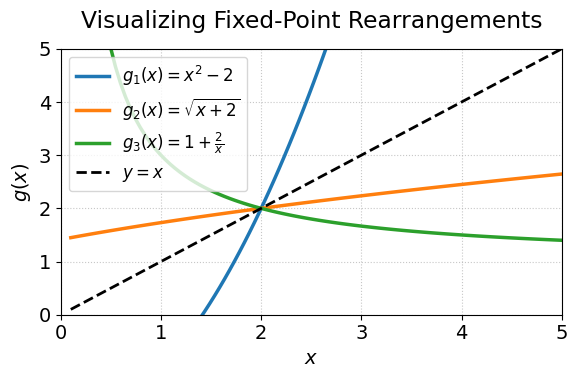

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the functions
def g1(x):
    return x**2 - 2.0

def g2(x):
    return np.sqrt(x + 2.0)

def g3(x):
    return 1.0 + 2.0 / x

# functions
g_functions = {
    g1: r"$g_1(x) = x^2 - 2$",
    g2: r"$g_2(x) = \sqrt{x + 2}$",
    g3: r"$g_3(x) = 1 + \frac{2}{x}$"
}

# Generate x values (starting slightly above 0 to prevent division by zero in g3)
x = np.linspace(0.1, 5.0, 100)

plt.rc("font", size=14)
fig, ax = plt.subplots(figsize=(6, 4))

# Plot each g(x)
for func, label in g_functions.items():
    ax.plot(x, func(x), lw=2.5, label=label)

# Plot the diagonal line y = x
ax.plot(x, x, lw=2, ls='--', color='black', label=r"$y = x$")

ax.set_xlim([0.0, 5.0])
ax.set_ylim([0.0, 5.0])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$g(x)$")
ax.set_title("Visualizing Fixed-Point Rearrangements", pad=15)

# Add grid and legend
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='best', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# 1. Define the function
def g1(x):
    return x**2 - 2.0

# 2. Setup iteration parameters
x0 = 2.1  # Starting slightly away from the root x=2 to show divergence
n_iterations = 4  # It diverges so fast we only need a few steps!

# 3. Generate the sequence of coordinates for the cobweb plot
# We trace vertical lines to the curve, and horizontal lines to y=x
cx = [x0]
cy = [0.0]  # Start at the x-axis

x_curr = x0
for _ in range(n_iterations):
    y_curr = g1(x_curr)

    # Vertical line to the g(x) curve
    cx.append(x_curr)
    cy.append(y_curr)

    # Horizontal line to the y = x line
    cx.append(y_curr)
    cy.append(y_curr)

    x_curr = y_curr

# 4. Set up the plot figure
plt.rc("font", size=14)
fig, ax = plt.subplots(figsize=(5.2, 3.6))

# We need a wide range to capture the explosive divergence
x_vals = np.linspace(-1.0, 16.0, 400)
ax.plot(x_vals, g1(x_vals), lw=2.5, color='#1f77b4', label=r"$g_1(x) = x^2 - 2$")
ax.plot(x_vals, x_vals, lw=2, ls='--', color='black', label=r"$y = x$")

# Initialize the empty animated elements
cobweb_line, = ax.plot([], [], color='red', lw=2, marker='o', markersize=6, alpha=0.8)
current_point, = ax.plot([], [], 'ro', markersize=10) # Highlights the leading edge

ax.set_xlim([0.0, 10.0])
ax.set_ylim([0.0, 10.0])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$g(x)$")
ax.set_title("Fixed-Point Iteration (Plot for g1(x))", pad=15)
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='lower right')

# 5. Animation function
def animate(i):
    # i represents the index of the coordinate arrays to draw up to
    cobweb_line.set_data(cx[:i+1], cy[:i+1])
    current_point.set_data([cx[i]], [cy[i]])

    # Update title dynamically to show iteration progress
    iteration_number = i // 2  # Every 2 frames equals 1 full iteration step
    if i > 0:
        ax.set_title(f"Iteration {iteration_number}: $x = {cx[i]:.3f}$", pad=15)

    return cobweb_line, current_point

# 6. Create and display the animation
# frames=len(cx) ensures we iterate through every point in the cobweb sequence
anim = FuncAnimation(fig, animate, frames=len(cx), interval=800, blit=True, repeat_delay=3000)

plt.close() # Prevents duplicate static plot from rendering above the animation
HTML(anim.to_jshtml())

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# 1. Define the convergent function
def g2(x):
    return np.sqrt(x + 2.0)

# 2. Setup iteration parameters
x0 = 0.5  # Start away from the root (x=2) to watch it climb inward
n_iterations = 6  # 6 steps will show it settling onto the root nicely

# 3. Generate the sequence of coordinates for the cobweb plot
cx = [x0]
cy = [0.0]  # Start at the x-axis

x_curr = x0
for _ in range(n_iterations):
    y_curr = g2(x_curr)

    # Vertical line to the g(x) curve
    cx.append(x_curr)
    cy.append(y_curr)

    # Horizontal line to the y = x line
    cx.append(y_curr)
    cy.append(y_curr)

    x_curr = y_curr

# 4. Set up the plot figure with requested size (6, 4)
plt.rc("font", size=12)
fig, ax = plt.subplots(figsize=(5.2, 3.6))

# Narrower range since the behavior is bounded and well-behaved
x_vals = np.linspace(0.0, 4.0, 400)
ax.plot(x_vals, g2(x_vals), lw=2.5, color='#ff7f0e', label=r"$g_2(x) = \sqrt{x + 2}$")
ax.plot(x_vals, x_vals, lw=2, ls='--', color='black', label=r"$y = x$")

# Initialize the empty animated elements
cobweb_line, = ax.plot([], [], color='red', lw=2, marker='o', markersize=5, alpha=0.8)
current_point, = ax.plot([], [], 'ro', markersize=8)

ax.set_xlim([0.0, 3.5])
ax.set_ylim([0.0, 3.5])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$g(x)$")
ax.set_title("Fixed-Point Iteration Convergence", pad=15)
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='lower right')

# 5. Animation function
def animate(i):
    cobweb_line.set_data(cx[:i+1], cy[:i+1])
    current_point.set_data([cx[i]], [cy[i]])

    # Update title dynamically
    iteration_number = i // 2
    if i > 0:
        ax.set_title(f"Iteration {iteration_number}: $x = {cx[i]:.4f}$", pad=15)

    return cobweb_line, current_point

# 6. Create and display the animation
anim = FuncAnimation(fig, animate, frames=len(cx), interval=800, blit=True, repeat_delay=3000)

plt.close()
HTML(anim.to_jshtml())

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# 1. Define the spiraling convergent function
def g3(x):
    return 1.0 + 2.0 / x

# 2. Setup iteration parameters
x0 = 4.0  # Start at 4 to clearly show the inward spiraling pattern
n_iterations = 8  # A few extra steps to watch the spiral tighten

# 3. Generate the sequence of coordinates for the cobweb plot
cx = [x0]
cy = [0.0]  # Start at the x-axis

x_curr = x0
for _ in range(n_iterations):
    y_curr = g3(x_curr)

    # Vertical line to the g(x) curve
    cx.append(x_curr)
    cy.append(y_curr)

    # Horizontal line to the y = x line
    cx.append(y_curr)
    cy.append(y_curr)

    x_curr = y_curr

# 4. Set up the plot figure with requested size (6, 4)
plt.rc("font", size=12)
fig, ax = plt.subplots(figsize=(5.2, 3.6))

# X values start above 0 to prevent division by zero in the plot
x_vals = np.linspace(0.5, 5.0, 400)
ax.plot(x_vals, g3(x_vals), lw=2.5, color='#2ca02c', label=r"$g_3(x) = 1 + \frac{2}{x}$")
ax.plot(x_vals, x_vals, lw=2, ls='--', color='black', label=r"$y = x$")

# Initialize the empty animated elements
cobweb_line, = ax.plot([], [], color='red', lw=2, marker='o', markersize=5, alpha=0.8)
current_point, = ax.plot([], [], 'ro', markersize=8)

ax.set_xlim([0.0, 5.0])
ax.set_ylim([0.0, 5.0])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$g(x)$")
ax.set_title("Fixed-Point Iteration: Spiraling Convergence", pad=15)
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='lower right')

# 5. Animation function
def animate(i):
    cobweb_line.set_data(cx[:i+1], cy[:i+1])
    current_point.set_data([cx[i]], [cy[i]])

    # Update title dynamically
    iteration_number = i // 2
    if i > 0:
        ax.set_title(f"Iteration {iteration_number}: $x = {cx[i]:.4f}$", pad=15)

    return cobweb_line, current_point

# 6. Create and display the animation
anim = FuncAnimation(fig, animate, frames=len(cx), interval=800, blit=True, repeat_delay=3000)

plt.close()
HTML(anim.to_jshtml())

### Understanding convergence of Fixed-Point Iteration

Given the iterative scheme:

$x^{(k+1)} = g(x^{(k)}), \quad k = 0, 1, 2, \dots$

where $g(x)$ is continuous and differentiable on the interval $[a, b]$, and $\alpha \in [a,b]$ is a true fixed point such that

$\alpha = g(\alpha)$

Fixed-Point Iteration is guaranteed to converge to a unique root $\alpha \in [a, b]$ if:

1. $a \leq g(x) \leq b$ for all $x \in [a, b]$
   
2. $|g'(x)| \leq k < 1$ for some constant $k < 1$ across all $x \in [a, b]$

---

### Rule of Thumb

* $|g'(\alpha)| < 1$: The method converges (linearly)
  
* $|g'(\alpha)| > 1$: The method diverges (repels away from the root)

* Smaller values of $|g'(\alpha)|$ yield faster convergence.

---

### Applying to the examples we discussed

For $f(x) = x^2 - x - 2 = 0$, the root is **$\alpha = 2$**.

Let's evaluate $g'(\alpha)$ at this root for each rearrangement:

| Rearrangement | Derivative Formula $g'(x)$ | At Root $\alpha = 2$ | $|g'(\alpha)|$ | Expected Behavior |
| :--- | :--- | :--- | :--- | :--- |
| **$g_1(x) = x^2 - 2$** | $g_1'(x) = 2x$ | $g_1'(2) = 4$ | $4 > 1$ | Diverges (Explosive growth) |
| **$g_2(x) = \sqrt{x + 2}$** | $g_2'(x) = \frac{1}{2\sqrt{x + 2}}$ | $g_2'(2) = \frac{1}{4}$ | $0.25 < 1$ | Converges (Staircase pattern) |
| **$g_3(x) = 1 + \frac{2}{x}$** | $g_3'(x) = -\frac{2}{x^2}$ | $g_3'(2) = -\frac{1}{2}$ | $0.50 < 1$ | Converges (Spiraling pattern) |

### Newton-Raphson: A Special Case of Fixed-Point Iteration

In Newton's method, the iterative scheme is:

$x^{(k+1)} = x^{(k)} - \frac{f(x^{(k)})}{f'(x^{(k)})}$

Comparing this to the fixed-point formulation $x^{(k+1)} = g(x^{(k)})$, we define:

$g(x) = x - \frac{f(x)}{f'(x)}$

---

Taking the derivative $g'(x)$ using the quotient rule:

$g'(x) = 1 - \frac{[f'(x)]^2 - f(x)f''(x)}{[f'(x)]^2} = \frac{f(x)f''(x)}{[f'(x)]^2}$

Evaluating $g'(x)$ at the true root $\alpha$ (where $f(\alpha) = 0$):

$g'(\alpha) = \frac{0 \cdot f''(\alpha)}{[f'(\alpha)]^2} = 0$

Newton's method constructs a specific $g(x)$ such that **$g'(\alpha) = 0$**. Because the derivative vanishes at the root, the method jumps from standard **linear convergence** to **quadratic convergence**.

### Understanding the Order of Convergence

To understand why convergence rates differ, expand $g(x^{(k)})$ as a Taylor series around the true root $\alpha$:

$x^{(k+1)} = g(x^{(k)}) = g(\alpha) + g'(\alpha)(x^{(k)} - \alpha) + \frac{g''(\alpha)}{2!}(x^{(k)} - \alpha)^2 + \dots$

Since $\alpha = g(\alpha)$, subtract $\alpha$ from both sides to express the error $e_k = x^{(k)} - \alpha$:

$e_{k+1} = g'(\alpha) \cdot e_k + \frac{g''(\alpha)}{2} \cdot e_k^2 + \dots$

---

#### 1. Standard Fixed-Point Iteration ($p = 1$)

* Normally, $g'(\alpha) \neq 0$ (e.g., $|g'(\alpha)| = 0.25$ or $0.50$)
  
* As $e_k \to 0$, the linear term $g'(\alpha) \cdot e_k$ dominates all higher-order terms

* Result: $e_{k+1} \approx g'(\alpha) \cdot e_k^{\mathbf{1}} \implies \mathbf{p = 1}$ (Linear Convergence)

#### 2. Newton-Raphson Trick ($p = 2$)

* Newton designed $g(x) = x - \frac{f(x)}{f'(x)}$ specifically so that $g'(\alpha) = 0$, completely eliminating the linear $e_k$ term!
  
* The quadratic term takes over as the dominant error driver: $\frac{g''(\alpha)}{2} \cdot e_k^2$.

* Result: $e_{k+1} \approx C \cdot e_k^{\mathbf{2}} \implies \mathbf{p = 2}$ (Quadratic Convergence).

<span style="color:#c62828">Question: If Newton-Raphson converges quadratically, why don't we use it for everything?</span>

Newton's method is locally quadratic ($p = 2$). However, if our initial guess $x_0$ is outside the basin of attraction—or if $f'(x) \approx 0$—it can easily diverge, oscillate infinitely, or crash.

---

To guarantee both 100% convergence and high speed, modern numerical libraries use **hybrid algorithms**:

1. *Global Search:* Start with robust bracketed methods (like Bisection) to shrink the interval containing the root until safety criteria are met.
2. *Local Speedup:* Switch to high-speed methods (like Newton or Secant) once inside the convergence basin.
3. *Safety:* If a Newton/Secant step lands outside the bracket or converges too slowly, the solver immediately drops back to a safe Bisection step.

---

These foundational methods are far from obsolete—they form the core engine of modern science and engineering software:

* `scipy.optimize.brentq` combines guaranteed Bisection steps with high-speed Secant steps.
* `scipy.optimize.newton` uses standard Newton-Raphson
* `scipy.optimize.root` and `scipy.optimize.fsolve` rely on Newton’s method and Quasi-Newton variants to solve multivariable Systems

The key takeaway is that the solvers are built not just for speed ($p=2$) but also for robustness.


## Systems of Non-Linear Equations

A system of $n$ *coupled* non-linear equations in $n$ unknowns is represented as a vector-valued function mapping from $n$-dimensional real space to $n$-dimensional real space:

$\mathbf{F}: \mathbb{R}^n \to \mathbb{R}^n$

expressed as:

$\mathbf{F}(\mathbf{x}) = \begin{bmatrix} f_1(x_1, x_2, \dots, x_n) \\ f_2(x_1, x_2, \dots, x_n) \\ \vdots \\ f_n(x_1, x_2, \dots, x_n) \end{bmatrix} = \mathbf{0}$

### Objective
Find a solution vector $\mathbf{x}^* = [x_1^*, x_2^*, \dots, x_n^*]^T \in \mathbb{R}^n$ that satisfies all component equations *simultaneously*:

$f_i(\mathbf{x}^*) = 0 \quad \text{for all } i = 1, 2, \dots, n$

$\mathbf{F}(\mathbf{x}^*) = \mathbf{0}$


### Note

* Solving n simultaneous, nonlinear equations is a much more formidable task than finding the root of a single equation
* The trouble is there is no a reliable method for bracketing the solution vector $\mathbf{x}$
* Therefore, we cannot always provide the solution algorithm with a good starting value of $\mathbf{x}$, unless such a value is suggested by the
physics of the problem.

### Example of a Nonlinear system

$f_1(x_1, x_2) = 1 + x_1 - x_2^2 = 0$

$f_2(x_1, x_2) = x_2 - x_1^3 = 0$


---

### Multivariable Fixed Point Iteration

To apply Fixed-Point Iteration, we isolate $x_1$ and $x_2$ to create iteration functions $g_1$ and $g_2$:

$x_1 = x_2^{1/3} \equiv g_1(x_1, x_2)$

$x_2 = \sqrt{1 + x_1} \equiv g_2(x_1, x_2)$

We can express this in vector form:

$$\mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \end{bmatrix}, \quad \mathbf{G}(\mathbf{x}) = \begin{bmatrix} g_1(x_1, x_2) \\ g_2(x_1, x_2) \end{bmatrix} = \begin{bmatrix} x_2^{1/3} \\[0.3em] \sqrt{1 + x_1} \end{bmatrix}$$

Now, if our initial guess vector is: $\mathbf{x}^{(0)} = \begin{bmatrix} 1.5 \\ 1.5 \end{bmatrix}$

Then, our first iteration step can be written as:

$$\mathbf{x}^{(1)} = \mathbf{G}\left(\mathbf{x}^{(0)}\right) = \begin{bmatrix} g_1(1.5, 1.5) \\[0.3em] g_2(1.5, 1.5) \end{bmatrix} = \begin{bmatrix} (1.5)^{1/3} \\[0.3em] \sqrt{1 + 1.5} \end{bmatrix} \approx \begin{bmatrix} 1.1447 \\ 1.5811 \end{bmatrix}$$

---

For a system of $n$ non-linear equations with $n$ unknown variables:

$$\mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \\ \vdots \\ x_n \end{bmatrix} \in \mathbb{R}^n, \quad \mathbf{G}(\mathbf{x}) = \begin{bmatrix} g_1(x_1, x_2, \dots, x_n) \\ g_2(x_1, x_2, \dots, x_n) \\ \vdots \\ g_n(x_1, x_2, \dots, x_n) \end{bmatrix} \in \mathbb{R}^n$$

The compact linear algebra iteration rule remains identical regardless of dimension:

$\mathbf{x}^{(k+1)} = \mathbf{G}\left(\mathbf{x}^{(k)}\right)$

**Multivariable Fixed-Point Iteration (FPI):**

Transform the system $\mathbf{F}(\mathbf{x}) = \mathbf{0}$ into an equivalent fixed-point map. The root $\mathbf{\alpha}$ then satisfies $\mathbf{\alpha} = \mathbf{G}(\mathbf{\alpha})$.

---



In [ ]:
import numpy as np
import pandas as pd

# F(x) = [f1(x), f2(x)]^T = 0
def F(x):
    x1, x2 = x[0], x[1]
    f1 = 1 + x1 - x2**2
    f2 = x2 - x1**3
    return np.array([f1, f2])

# G(x) = [g1(x), g2(x)]^T
def G(x):
    x1, x2 = x[0], x[1]
    g1 = x2**(1/3)
    g2 = np.sqrt(1 + x1)
    return np.array([g1, g2])

# Fixed-Point Iteration Solver in 2D
def fixed_point_iteration_2d(x0, max_iter=10, tol=1e-6):
    x = np.array(x0, dtype=float)
    history = []

    for k in range(max_iter):
        residuals = F(x)
        res_norm = np.linalg.norm(residuals) # Euclidean norm ||F(x)||

        # Record history for display
        history.append({
            'k': k,
            'x_1': x[0],
            'x_2': x[1],
            'f_1(x1, x2)': residuals[0],
            'f_2(x1, x2)': residuals[1],
            '||F(x)||': res_norm
        })

        # Check stopping criterion
        if res_norm < tol:
            break

        # Perform vector update: x^{(k+1)} = G(x^{(k)})
        x = G(x)

    return pd.DataFrame(history)

# --- RUN ITERATION ---
x0 = [1.5, 1.5]
df_results = fixed_point_iteration_2d(x0, max_iter=12)

# Pandas DataFrame
pd.set_option('display.float_format', lambda x: f'{x:10.6f}')
df_results

,k,x_1,x_2,"f_1(x1, x2)","f_2(x1, x2)",||F(x)||
0,0,1.500000,1.500000,0.250000,-1.875000,1.891593
1,1,1.144714,1.581139,-0.355286,0.081139,0.364433
2,2,1.164993,1.464484,0.020279,-0.116655,0.118404
3,3,1.135607,1.471392,-0.029386,0.006907,0.030186
4,4,1.137390,1.461372,0.001783,-0.010020,0.010177
5,5,1.134802,1.461982,-0.002588,0.000610,0.002659
6,6,1.134960,1.461096,0.000158,-0.000885,0.000899
7,7,1.134731,1.461150,-0.000229,0.000054,0.000235
8,8,1.134745,1.461072,0.000014,-0.000078,0.000080
9,9,1.134725,1.461077,-0.000020,0.000005,0.000021


### Multivariable Newton-Raphson Method

Let $\mathbf{F}(\mathbf{x})$ be a vector-valued function of $n$ variables:

$$\mathbf{F}(\mathbf{x}) = \begin{bmatrix} f_{1}(x_{1}, x_{2}, \dots, x_{n}) \\ f_{2}(x_{1}, x_{2}, \dots, x_{n}) \\ \vdots \\ f_{n}(x_{1}, x_{2}, \dots, x_{n}) \end{bmatrix}$$

**From 1D to $n$-Dimensions**

In 1D scalar root-finding, Newton's method uses the derivative $f'(x)$ to construct the update:

$x^{(k+1)} = x^{(k)} - \frac{f(x^{(k)})}{f'(x^{(k)})}$

In $n$-dimensions, the single derivative $f'(x)$ is replaced by the **Jacobian matrix** $\mathbf{J}_{\mathbf{F}}(\mathbf{x})$, and we update iteration step using matrix inversion:

$\mathbf{x}^{(k+1)} = \mathbf{x}^{(k)} - \left[\mathbf{J}_{\mathbf{F}}\left(\mathbf{x}^{(k)}\right)\right]^{-1} \mathbf{F}\left(\mathbf{x}^{(k)}\right)$

---

The **Jacobian matrix** $\mathbf{J}_{\mathbf{F}}(\mathbf{x})$ contains all first-order partial derivatives of each function with respect to each variable:

$$\mathbf{J}_{\mathbf{F}}(\mathbf{x}) = \begin{bmatrix}
\frac{\partial f_{1}}{\partial x_{1}} & \frac{\partial f_{1}}{\partial x_{2}} & \dots & \frac{\partial f_{1}}{\partial x_{n}} \\[0.5em]
\frac{\partial f_{2}}{\partial x_{1}} & \frac{\partial f_{2}}{\partial x_{2}} & \dots & \frac{\partial f_{2}}{\partial x_{n}} \\[0.5em]
\vdots & \vdots & \ddots & \vdots \\[0.5em]
\frac{\partial f_{n}}{\partial x_{1}} & \frac{\partial f_{n}}{\partial x_{2}} & \dots & \frac{\partial f_{n}}{\partial x_{n}}
\end{bmatrix}$$

We update the Jacobian at each iteration. It holds $n^2$ partial derivatives.

When analytical derivatives are hard or costly, we approximate them with forward finite differences:

$\frac{\partial f_{i}(\mathbf{x}^{(k)})}{\partial x_{j}} \approx \frac{f_{i}(\mathbf{x}^{(k)} + h\mathbf{e}_{j}) - f_{i}(\mathbf{x}^{(k)})}{h}$

---

Computing the explicit inverse $\mathbf{J}^{-1}$ is expensive $O(n^3)$

Instead of inverting $\mathbf{J}$, we rewrite the iteration in terms of a linear system step:

$\mathbf{x}^{(k+1)} = \mathbf{x}^{(k)} + \Delta \mathbf{x}^{(k)}$

where the update step $\Delta \mathbf{x}^{(k)}$ is calculated by solving the standard linear system $\mathbf{A}\mathbf{x} = \mathbf{b}$:

$\mathbf{J}_{\mathbf{F}}\left(\mathbf{x}^{(k)}\right) \Delta \mathbf{x}^{(k)} = -\mathbf{F}\left(\mathbf{x}^{(k)}\right)$

Here:
* $\mathbf{A} = \mathbf{J}_{\mathbf{F}}\left(\mathbf{x}^{(k)}\right)$ (Jacobian matrix / Coefficient matrix)
* $\mathbf{x} = \Delta \mathbf{x}^{(k)}$ (Unknown step vector)
* $\mathbf{b} = -\mathbf{F}\left(\mathbf{x}^{(k)}\right)$ (Negative residual vector)

We solve for $\Delta \mathbf{x}^{(k)}$ with a standard linear solver (LU decomposition or iterative methods). This connects multivariable root-finding back to our lecture on linear systems.

In [ ]:
import numpy as np
import pandas as pd

# F(x) = [f1(x), f2(x)]^T = 0
def F(x):
    x1, x2 = x[0], x[1]
    f1 = 1 + x1 - x2**2
    f2 = x2 - x1**3
    return np.array([f1, f2])

# Jacobian Matrix: J(x)
def J(x):
    x1, x2 = x[0], x[1]
    df1_dx1, df1_dx2 = 1.0, -2.0 * x2
    df2_dx1, df2_dx2 = -3.0 * (x1**2), 1.0

    return np.array([
        [df1_dx1, df1_dx2],
        [df2_dx1, df2_dx2]
    ])

# Multivariable Newton-Raphson Solver
def multivariable_newton_raphson(x0, max_iter=10, tol=1e-8):
    x = np.array(x0, dtype=float)
    history = []

    for k in range(max_iter):
        residuals = F(x)
        res_norm = np.linalg.norm(residuals) # Euclidean norm ||F(x)||
        J_mat = J(x)                          # Evaluate Jacobian matrix

        # Solve the linear system: J * dx = -F  (Avoids computing J^-1 directly)
        dx = np.linalg.solve(J_mat, -residuals)
        dx_norm = np.linalg.norm(dx)          # Step size ||dx||

        # Record iteration history
        history.append({
            'k': k,
            'x_1': x[0],
            'x_2': x[1],
            'f_1(x1, x2)': residuals[0],
            'f_2(x1, x2)': residuals[1],
            '||F(x)||': res_norm,
            '||dx||': dx_norm
        })

        # Convergence check: stop if residual or step size is below tolerance
        if res_norm < tol or dx_norm < tol:
            break

        # Update solution vector: x^{(k+1)} = x^{(k)} + dx^{(k)}
        x = x + dx

    return pd.DataFrame(history)

# --- RUN SOLVER ---
x0 = [1.5, 1.5]
df_newton = multivariable_newton_raphson(x0, max_iter=10, tol=1e-8)

# Display iterative steps as panda dataframe
pd.set_option('display.float_format', lambda x: f'{x:12.8f}')
df_newton

,k,x_1,x_2,"f_1(x1, x2)","f_2(x1, x2)",||F(x)||,||dx||
0,0,1.50000000,1.50000000,0.25000000,-1.87500000,1.89159324,0.27939062
1,1,1.22077922,1.49025974,-0.00009487,-0.32906986,0.32906987,0.08395160
2,2,1.14119751,1.46352729,-0.00071462,-0.02269048,0.02270173,0.00688049
3,3,1.13476488,1.46108550,-0.00000596,-0.00014140,0.00014152,0.00004376
4,4,1.13472414,1.46106952,-0.00000000,-0.00000001,0.00000001,0.00000000


### Multivariable Newton-Raphson Algorithm

By leveraging linear algebra, the multivariable Newton-Raphson algorithm reduces to a simple iterative loop:

---
**Pseudocode**

```text
x = x0

FOR k = 1 TO maxiter DO
    F_x = F(x)                          # Evaluate residual vector
    J_x = J(x)                          # Evaluate Jacobian matrix
    
    dx  = SolveLinearSystem(J_x, -F_x)  # Solve J_x * dx = -F_x for step dx
    x   = x + dx                        # Update state vector
    
    IF Norm(dx) < tol THEN
        RETURN x                        # Convergence reached
    END IF
END FOR

RAISE ERROR "Failed to converge within maxiter steps"
```
---

### Brief Note About Other Methods: Broyden's Method

In 1D, the secant method sometimes beats Newton's method, and practical solvers often mix approaches.

Based on a similar idea, **Broyden's Method** adapts the secant method for systems of nonlinear equations.

In the 1D secant method, $f'(x)$ is replaced by:

$f'(x^{(1)}) \approx \frac{f(x^{(1)}) - f(x^{(0)})}{x^{(1)} - x^{(0)}}$

which can be rewritten as:

$f'(x^{(1)})(x^{(1)} - x^{(0)}) \approx f(x^{(1)}) - f(x^{(0)})$

Now, the $n$-variable vector equivalent is:

$\mathbf{J}_{\mathbf{F}}(\mathbf{x}^{(1)})(\mathbf{x}^{(1)} - \mathbf{x}^{(0)}) \approx \mathbf{F}(\mathbf{x}^{(1)}) - \mathbf{F}(\mathbf{x}^{(0)})$

Instead of evaluating the full Jacobian $\mathbf{J}_{\mathbf{F}}$, Broyden's method seeks an approximate matrix $\mathbf{A}_1$ that satisfies the secant condition:

$\mathbf{A}_1(\mathbf{x}^{(1)} - \mathbf{x}^{(0)}) = \mathbf{F}(\mathbf{x}^{(1)}) - \mathbf{F}(\mathbf{x}^{(0)})$

---

#### How to determine Matrix $\mathbf{A}$

We have $n$ equations, but we need $n^2$ matrix entries

To fix the remaining $n^2 - n$ degrees of freedom, Broyden introduced a strategy:

* Along the step (or secant direction), we enforce the condition:

$\mathbf{A}_{k+1} \Delta \mathbf{x}_k = \Delta \mathbf{F}_k$
  
* Perpendicular direction: In $n$-dimensional space $\mathbb{R}^n$, the subspace orthogonal to $\Delta \mathbf{x}_k$ has a dimension of $n - 1$. Let $\{\mathbf{u}_1, \mathbf{u}_2, \dots, \mathbf{u}_{n-1}\}$ be an orthogonal basis for this perpendicular subspace. For each of these $n - 1$ basis vectors, we enforce:

$\mathbf{A}_{k+1} \mathbf{u} = \mathbf{A}_k \mathbf{u}$

Combining these two rules yields $\mathbf{A}$ matrix:

$\mathbf{A}_{k+1} = \mathbf{A}_k + \frac{\Delta \mathbf{F}_k - \mathbf{A}_k \Delta \mathbf{x}_k}{\|\Delta \mathbf{x}_k\|_2^2} \Delta \mathbf{x}_k^T$

where, $\mathbf{A}_k$ is the current estimated Jacobian matrix

---

#### Efficiency & Operational Cost

Broyden's method requires $O(n^2)$ matrix-vector operations per iteration.

This achieves superior efficiency over standard Newton-Raphson by bypassing the need to compute $n^2$ partial derivatives ($n+1$ function calls) at every single step.

---

### Summary

* Existence and uniqueness of solutions are more complicated for nonlinear equations than for linear equations

* Nonlinear equations can have any number of solutions

* In Newton's method, the search step $\Delta \mathbf{x}_k$ is found by solving $\mathbf{J}(\mathbf{x}_k) \Delta \mathbf{x}_k = -\mathbf{F}(\mathbf{x}_k)$

* Root is ill-conditioned if Jacobian matrix is nearly singular

* When condition number is large $\kappa(\mathbf{J}) \gg 1$, small perturbations in either $\mathbf{F}(\mathbf{x})$ or $\mathbf{J}(\mathbf{x})$ lead to massive errors in the step vector $\Delta \mathbf{x}_k$

* Hybrid methods combine features of both types of methods to achieve both speed and reliability

* Root-finding is framed as a minimization problem to enable global convergence strategies when pure Newton's method fails.